# Network Intrusion Detection

## MCA Final-Year PBL Project - SEC D

**Project goal:** classify a network-flow record as **Normal Traffic** or **Malicious Traffic**. This notebook explores the data, trains and compares Logistic Regression, Decision Tree, and Random Forest classifiers, performs cross-validation and hyperparameter tuning, evaluates on an untouched test set, saves the best complete pipeline, and lets you classify a new record.

### Student and project details

- **Student name(s):** Akash Ghosh______________________________
- **Roll number(s):** 25102410174___________________________
- **Course / section:** MCA Final-Year PBL - SEC D
- **Instructor:** Abhipsa Guha__________________________________________
- **Submission date:** 26.11.26_____________________________________

> **Scope:** this notebook uses the binary `label` column: `0` = normal and `1` = attack. The dataset also has `attack_cat`, which describes attack types. `attack_cat` is used for exploration and is excluded from model inputs because it reveals the answer. The official UNSW partition has 175,341 training rows and 82,332 test rows; the full raw dataset has about 2.54 million rows. Start with the provided train/test partitions because they are much easier to run on a student computer.


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set (1).csv
Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set.csv


## 1. Install or import the required tools

These libraries read and prepare data, draw charts, train classifiers, and save the fitted pipeline. If a package is missing, run the commented installation command in a notebook cell, then restart the kernel and run the notebook from the top.

In [ ]:
# If needed, remove the # and run this line once in Jupyter or Colab:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Download the dataset and choose the file paths

**Recommended source:** [Official UNSW-NB15 dataset page](https://research.unsw.edu.au/projects/unsw-nb15-dataset). Download and extract the provided files. The prepared partition files are named `UNSW_NB15_training-set.csv` and `UNSW_NB15_testing-set.csv`; keep them in the same folder. The archive also includes a feature-description file. Read it before interpreting individual fields.

The official page describes nine attack families and says the prepared training and test partitions contain 175,341 and 82,332 rows. The 2.54 million figure refers to the full dataset across four raw CSV files, not the smaller prepared partitions.

**What to enter:** for each prompt, type the complete file path or a path relative to this notebook, such as `data/UNSW_NB15_training-set.csv`. Do not include quotation marks. If you downloaded the files into a folder named `data`, press Enter to use the default paths.

**Optional Google Drive connection (Google Colab only):** keep this commented unless using Colab. After uncommenting and running it, enter the Drive file paths at the prompts below.

```python
# from google.colab import drive
# drive.mount('/content/drive')
```

**Optional Kaggle API for later:** configure Kaggle API credentials securely in the runtime first. Never paste a private token into a notebook you plan to share. The dataset slug below is a Kaggle mirror; the UNSW page above remains the recommended source.

```python
# %pip install kaggle
# !kaggle datasets download -d mrwellsdavid/unsw-nb15 -p data --unzip
# Then use the file prompts below to select the training and testing CSVs.
```


In [ ]:
train_path_text = input(
    "Training CSV path (Enter for data/UNSW_NB15_training-set.csv): "
).strip().strip('"').strip("'")
test_path_text = input(
    "Testing CSV path (Enter for data/UNSW_NB15_testing-set.csv): "
).strip().strip('"').strip("'")

train_path = Path(train_path_text) if train_path_text else Path("data/UNSW_NB15_training-set.csv")
test_path = Path(test_path_text) if test_path_text else Path("data/UNSW_NB15_testing-set.csv")

if not train_path.is_file():
    raise FileNotFoundError(
        "Training CSV not found at " + str(train_path) +
        ". Extract the UNSW-NB15 archive and enter the correct training CSV path."
    )
if not test_path.is_file():
    raise FileNotFoundError(
        "Testing CSV not found at " + str(test_path) +
        ". Extract the UNSW-NB15 archive and enter the correct testing CSV path."
    )

train_df = pd.read_csv(train_path, low_memory=False)
test_df = pd.read_csv(test_path, low_memory=False)
print("Training file:", train_path, "| shape:", train_df.shape)
print("Testing file:", test_path, "| shape:", test_df.shape)
display(train_df.head())

Training CSV path (Enter for data/UNSW_NB15_training-set.csv): "/content/UNSW_NB15_training-set.csv"
Testing CSV path (Enter for data/UNSW_NB15_testing-set.csv): "/content/UNSW_NB15_testing-set.csv"
Training file: /content/UNSW_NB15_training-set.csv | shape: (175341, 45)
Testing file: /content/UNSW_NB15_testing-set.csv | shape: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Understand the columns and target labels

We inspect column names, data types, missing values, and class counts. **Why:** this confirms the selected files have the expected schema and shows how many normal and malicious flows are available. The label column must contain `0` and `1`; other columns describe the network flow.

In [ ]:
print("Training columns:")
print(train_df.columns.tolist())
print("\nTraining data types and non-missing counts:")
train_df.info()
print("\nMissing values in training data (largest counts first):")
display(train_df.isna().sum().sort_values(ascending=False).head(15))
print("\nExact duplicate rows in training file:", train_df.duplicated().sum())

if "label" not in train_df.columns or "label" not in test_df.columns:
    raise ValueError("Expected a binary target column named 'label'. Check that you selected the prepared UNSW-NB15 partition files.")

print("\nTraining label counts (0 = Normal, 1 = Attack):")
display(train_df["label"].value_counts(dropna=False).sort_index().rename(index={0: "Normal (0)", 1: "Attack (1)"}).to_frame("Records"))
if "attack_cat" in train_df.columns:
    print("\nTraining attack-category counts:")
    display(train_df["attack_cat"].fillna("Missing").value_counts().to_frame("Records"))

Training columns:
['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']

Training data types and non-missing counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175341 entries, 0 to 175340
Data columns (total 45 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 175341 non-null  int64  
 1   dur                175341 non-null  float64
 2   proto              175341 non-null  object 
 3   service            175341 non-null  object 
 4   state     

,0
id,0
dur,0
proto,0
service,0
state,0
spkts,0
dpkts,0
sbytes,0
dbytes,0
rate,0



Exact duplicate rows in training file: 0

Training label counts (0 = Normal, 1 = Attack):


,Records
label,
Normal (0),56000
Attack (1),119341



Training attack-category counts:


,Records
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


## 4. Explore the training data

We plot the normal-versus-attack balance, the attack categories, and a few numeric network-flow measurements. **Why:** class imbalance can make accuracy look better than attack detection really is, and feature charts give useful context before modeling. These plots use training data only.

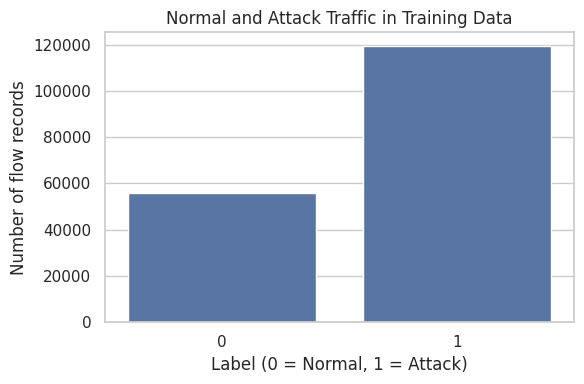

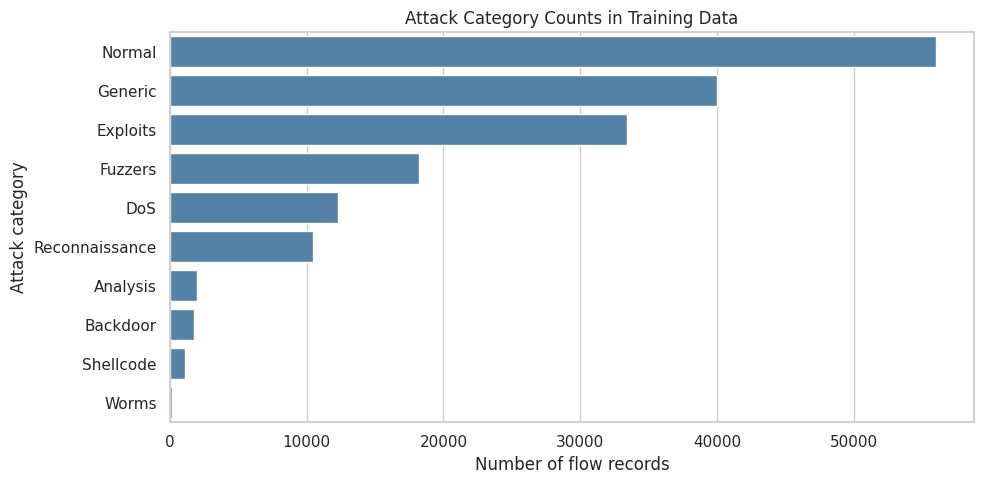

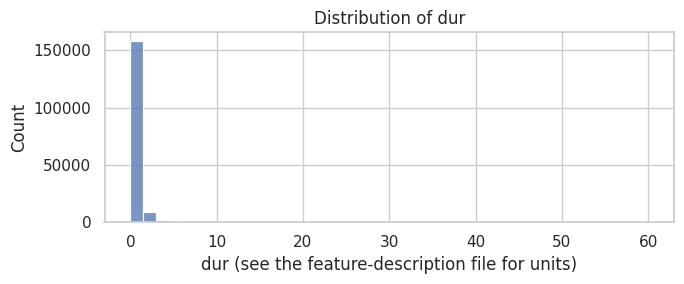

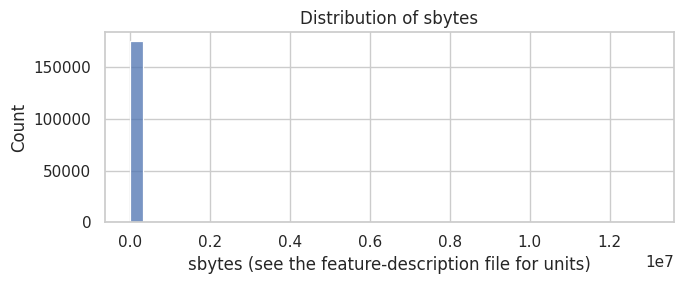

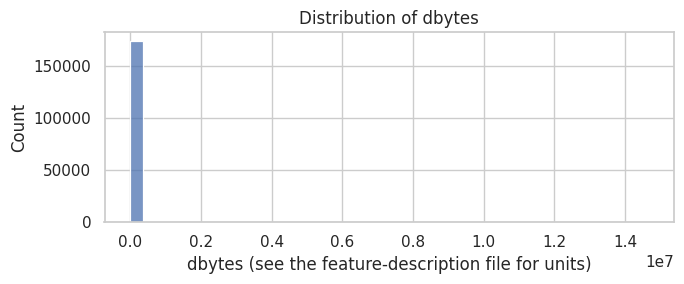

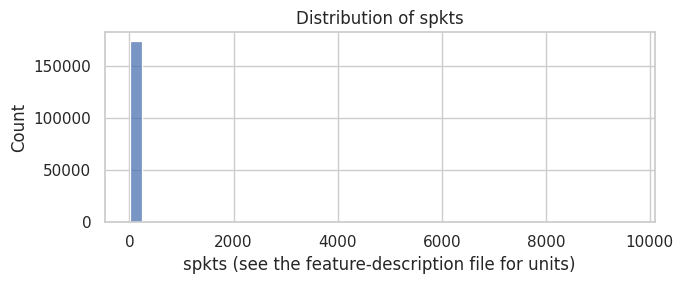

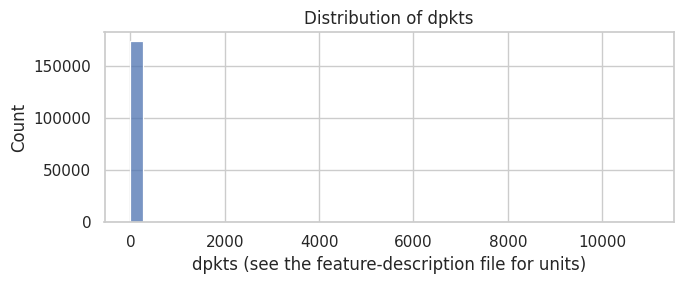

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=train_df, x="label", order=[0, 1])
plt.title("Normal and Attack Traffic in Training Data")
plt.xlabel("Label (0 = Normal, 1 = Attack)")
plt.ylabel("Number of flow records")
plt.tight_layout()
plt.show()

if "attack_cat" in train_df.columns:
    attack_counts = train_df["attack_cat"].fillna("Missing").value_counts()
    plt.figure(figsize=(10, 5))
    sns.barplot(x=attack_counts.values, y=attack_counts.index, color="steelblue")
    plt.title("Attack Category Counts in Training Data")
    plt.xlabel("Number of flow records")
    plt.ylabel("Attack category")
    plt.tight_layout()
    plt.show()

for feature in ["dur", "sbytes", "dbytes", "spkts", "dpkts"]:
    if feature in train_df.columns:
        values = pd.to_numeric(train_df[feature], errors="coerce")
        plt.figure(figsize=(7, 3))
        sns.histplot(values.replace([np.inf, -np.inf], np.nan).dropna(), bins=40)
        plt.title("Distribution of " + feature)
        plt.xlabel(feature + " (see the feature-description file for units)")
        plt.tight_layout()
        plt.show()

## 5. Prepare input features and the binary target

The target `y` is `label`. We exclude `id` because it is a row identifier and exclude `attack_cat` because it directly reveals the attack label. **Why:** including an answer-derived field would create target leakage and misleadingly high scores. Numeric missing or infinite values are handled by the preprocessing pipeline; categorical values are encoded there too.

In [ ]:
target_column = "label"
leakage_or_identifier_columns = ["id", "attack_cat", target_column]
feature_columns = [
    column for column in train_df.columns
    if column not in leakage_or_identifier_columns
]

missing_test_features = [column for column in feature_columns if column not in test_df.columns]
if missing_test_features:
    raise ValueError("Testing file is missing training features: " + ", ".join(missing_test_features))

X = train_df[feature_columns].copy()
y = pd.to_numeric(train_df[target_column], errors="coerce")
valid_target = y.notna()
X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].astype(int).reset_index(drop=True)

X_test_official = test_df[feature_columns].copy()
y_test_official = pd.to_numeric(test_df[target_column], errors="coerce")
valid_test_target = y_test_official.notna()
X_test_official = X_test_official.loc[valid_test_target].reset_index(drop=True)
y_test_official = y_test_official.loc[valid_test_target].astype(int).reset_index(drop=True)

# Convert infinite numeric values into missing values so the imputer can handle them.
for frame in [X, X_test_official]:
    numeric_columns_found = frame.select_dtypes(include=np.number).columns
    frame.loc[:, numeric_columns_found] = frame.loc[:, numeric_columns_found].replace([np.inf, -np.inf], np.nan)

print("Selected input columns:", len(feature_columns))
print("Identifier/answer-related columns excluded:", leakage_or_identifier_columns)
print("Training features:", X.shape, "| Official test features:", X_test_official.shape)
print("Target labels present:", sorted(y.unique().tolist()))

Selected input columns: 42
Identifier/answer-related columns excluded: ['id', 'attack_cat', 'label']
Training features: (175341, 42) | Official test features: (82332, 42)
Target labels present: [0, 1]


## 6. Make a stratified training and validation split

The official training file is split into 80% training data and 20% validation data. The official testing file stays untouched until final evaluation. **Why:** validation helps compare model settings while the official test set remains a fair final check. Stratification keeps the normal/attack proportions similar across the internal split.

In [ ]:
X_train, X_validation, y_train, y_validation = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Model-training subset:", X_train.shape, "| Validation subset:", X_validation.shape)
print("Official test set (held aside):", X_test_official.shape)
print("Training labels:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "Normal (0)", 1: "Attack (1)"}).mul(100).round(2).to_frame("Percent"))

Model-training subset: (140272, 42) | Validation subset: (35069, 42)
Official test set (held aside): (82332, 42)
Training labels:


,Percent
label,
Normal (0),31.94
Attack (1),68.06


## 7. Build reusable preprocessing and model pipelines

Numeric fields are median-imputed and scaled. Categorical fields are filled with their most common value and one-hot encoded. **Why:** classifiers need consistent numeric inputs, and a pipeline applies the same transformations during cross-validation, tuning, evaluation, saving, and future prediction. Unknown categories in new traffic are safely ignored by the encoder.

In [ ]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Numeric features:", len(numeric_features))
print("Categorical features:", categorical_features)

Numeric features: 39
Categorical features: ['proto', 'service', 'state']


## 8. Train three baseline classifiers

We fit Logistic Regression, a Decision Tree, and a Random Forest on the same training subset. **Why:** the models learn in different ways, so comparing them helps identify useful trade-offs. Class weights reduce the chance that a model ignores the less common class.

In [ ]:
baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, solver="liblinear", class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1
    )
}

baseline_pipelines = {
    name: Pipeline([("preprocessor", preprocessor), ("model", model)])
    for name, model in baseline_models.items()
}

def classification_scores(model, features, labels):
    predictions = model.predict(features)
    return {
        "Accuracy": accuracy_score(labels, predictions),
        "Attack precision": precision_score(labels, predictions, pos_label=1, zero_division=0),
        "Attack recall": recall_score(labels, predictions, pos_label=1, zero_division=0),
        "Attack F1": f1_score(labels, predictions, pos_label=1, zero_division=0)
    }

baseline_rows = []
for model_name, model_pipeline in baseline_pipelines.items():
    print("Training:", model_name)
    model_pipeline.fit(X_train, y_train)
    scores = classification_scores(model_pipeline, X_validation, y_validation)
    baseline_rows.append({"Model": model_name, **scores})

baseline_results = pd.DataFrame(baseline_rows).sort_values("Attack F1", ascending=False)
print("Validation performance (attack is the positive class):")
display(baseline_results.round(4))

Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Validation performance (attack is the positive class):


,Model,Accuracy,Attack precision,Attack recall,Attack F1
2,Random Forest,0.9591,0.9641,0.9762,0.9701
1,Decision Tree,0.9479,0.9626,0.9609,0.9617
0,Logistic Regression,0.9326,0.9502,0.9509,0.9505


## 9. Evaluate baseline models with confusion matrices

The confusion matrix shows correct and incorrect normal/attack predictions. **Why:** an attack classified as normal is a false negative and may be especially costly in an intrusion-detection setting. Recall measures how many actual attacks were found; precision measures how many attack alerts were truly attacks.


 Logistic Regression
              precision    recall  f1-score   support

      Normal       0.90      0.89      0.89     11200
      Attack       0.95      0.95      0.95     23869

    accuracy                           0.93     35069
   macro avg       0.92      0.92      0.92     35069
weighted avg       0.93      0.93      0.93     35069



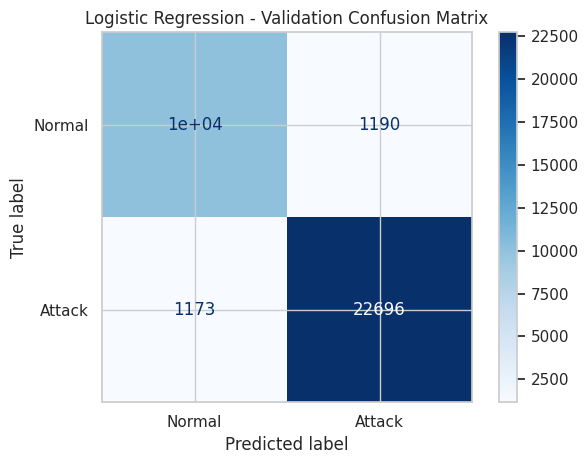


 Decision Tree
              precision    recall  f1-score   support

      Normal       0.92      0.92      0.92     11200
      Attack       0.96      0.96      0.96     23869

    accuracy                           0.95     35069
   macro avg       0.94      0.94      0.94     35069
weighted avg       0.95      0.95      0.95     35069



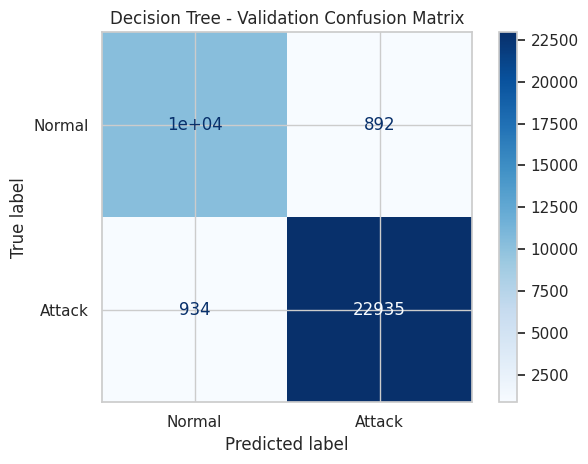


 Random Forest
              precision    recall  f1-score   support

      Normal       0.95      0.92      0.94     11200
      Attack       0.96      0.98      0.97     23869

    accuracy                           0.96     35069
   macro avg       0.96      0.95      0.95     35069
weighted avg       0.96      0.96      0.96     35069



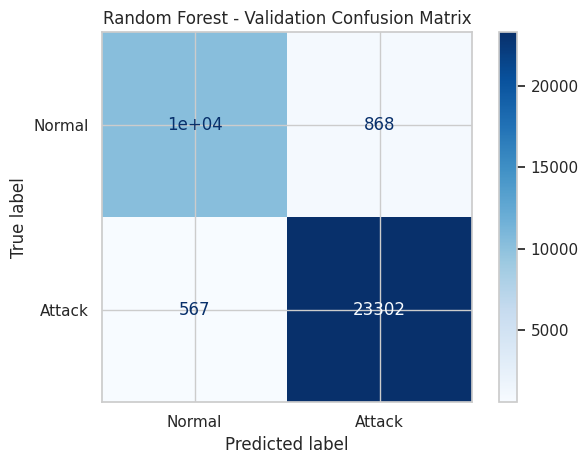

In [ ]:
for model_name, model_pipeline in baseline_pipelines.items():
    validation_prediction = model_pipeline.predict(X_validation)
    print("\n", model_name)
    print(classification_report(
        y_validation, validation_prediction,
        labels=[0, 1], target_names=["Normal", "Attack"], zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_validation, validation_prediction,
        labels=[0, 1], display_labels=["Normal", "Attack"], cmap="Blues"
    )
    plt.title(model_name + " - Validation Confusion Matrix")
    plt.tight_layout()
    plt.show()

## 10. Five-fold cross-validation on training data

Five-fold stratified cross-validation repeats training and validation across five balanced folds. To keep runtime reasonable, it uses a representative sample of up to 15,000 rows from the training subset. **Why:** folds show whether the model's attack F1 is reasonably stable across different portions of training data. This sample is only for model selection; the final model is refit on all official training rows.

In [ ]:
cv_row_limit = min(15000, len(X_train))
if cv_row_limit < len(X_train):
    X_cv, _, y_cv, _ = train_test_split(
        X_train, y_train, train_size=cv_row_limit,
        random_state=42, stratify=y_train
    )
else:
    X_cv, y_cv = X_train, y_train

five_fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for model_name, model_pipeline in baseline_pipelines.items():
    scores = cross_validate(
        model_pipeline, X_cv, y_cv, cv=five_fold,
        scoring={"attack_f1": "f1", "attack_recall": "recall", "accuracy": "accuracy"},
        n_jobs=-1, return_train_score=False
    )
    for fold_index, (f1_value, recall_value, accuracy_value) in enumerate(zip(
        scores["test_attack_f1"], scores["test_attack_recall"], scores["test_accuracy"]
    ), start=1):
        cv_rows.append({
            "Model": model_name, "Fold": fold_index,
            "Attack F1": f1_value, "Attack recall": recall_value,
            "Accuracy": accuracy_value
        })

cv_results = pd.DataFrame(cv_rows)
print("Per-fold validation scores:")
display(cv_results.round(4))
print("Average and standard deviation across five folds:")
display(cv_results.groupby("Model")[["Attack F1", "Attack recall", "Accuracy"]].agg(["mean", "std"]).round(4))

Per-fold validation scores:


,Model,Fold,Attack F1,Attack recall,Accuracy
0,Logistic Regression,1,0.9516,0.9574,0.9337
1,Logistic Regression,2,0.9482,0.9584,0.9287
2,Logistic Regression,3,0.9559,0.9613,0.9397
3,Logistic Regression,4,0.9463,0.9452,0.9270
4,Logistic Regression,5,0.9585,0.9569,0.9437
5,Decision Tree,1,0.9427,0.9422,0.9220
6,Decision Tree,2,0.9480,0.9456,0.9293
7,Decision Tree,3,0.9526,0.9545,0.9353
8,Decision Tree,4,0.9456,0.9452,0.9260
9,Decision Tree,5,0.9580,0.9554,0.9430


Average and standard deviation across five folds:


Attack F1         Attack recall         Accuracy        
                         mean     std          mean     std     mean     std
Model                                                                       
Decision Tree          0.9494  0.0060        0.9486  0.0060   0.9311  0.0082
Logistic Regression    0.9521  0.0051        0.9558  0.0062   0.9345  0.0071
Random Forest          0.9620  0.0045        0.9768  0.0031   0.9474  0.0064

## 11. Tune all three models with GridSearchCV

GridSearchCV compares a small set of settings using three-fold stratified cross-validation on up to 12,000 training rows. **Why:** tuning can improve attack detection while keeping the search practical on a laptop. Attack F1 is used to balance finding attacks with limiting false alarms. The untouched official test data is not used in this search.

In [ ]:
grid_row_limit = min(12000, len(X_train))
if grid_row_limit < len(X_train):
    X_grid, _, y_grid, _ = train_test_split(
        X_train, y_train, train_size=grid_row_limit,
        random_state=43, stratify=y_train
    )
else:
    X_grid, y_grid = X_train, y_train

tuning_estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, solver="liblinear", class_weight="balanced", random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        class_weight="balanced_subsample", random_state=42, n_jobs=-1
    )
}
parameter_grids = {
    "Logistic Regression": {"model__C": [0.1, 1.0]},
    "Decision Tree": {
        "model__max_depth": [10, 20],
        "model__min_samples_leaf": [1, 5]
    },
    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [15, None]
    }
}

tuned_models = {}
tuning_rows = []
three_fold = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
for model_name, estimator in tuning_estimators.items():
    print("Searching settings for:", model_name)
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameter_grids[model_name],
        scoring="f1", cv=three_fold, n_jobs=-1,
        refit=True, return_train_score=False
    )
    search.fit(X_grid, y_grid)
    tuned_models[model_name] = search.best_estimator_
    tuning_rows.append({
        "Model": model_name,
        "Best CV attack F1": search.best_score_,
        "Best parameters": search.best_params_
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values("Best CV attack F1", ascending=False)
print("Best settings from training-fold cross-validation:")
display(tuning_results)

Searching settings for: Logistic Regression
Searching settings for: Decision Tree
Searching settings for: Random Forest
Best settings from training-fold cross-validation:


,Model,Best CV attack F1,Best parameters
2,Random Forest,0.960074,"{'model__max_depth': None, 'model__n_estimator..."
0,Logistic Regression,0.946758,{'model__C': 1.0}
1,Decision Tree,0.944045,"{'model__max_depth': 10, 'model__min_samples_l..."


In [ ]:
import os
import joblib

model_folder = (
    "/content/drive/MyDrive/"
    "Network_Intrusion_Detection/models"
)

os.makedirs(model_folder, exist_ok=True)

for name, model in tuned_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        os.path.join(model_folder, filename)
    )

print("All three models saved successfully!")

All three models saved successfully!


## 12. Select the best tuned model and evaluate the untouched test set

The model with the highest cross-validation attack F1 is selected using training data only. It is refit on the complete official training partition and evaluated once on the official test partition. **Why:** the final scores then provide a fairer estimate of performance on unseen records.

Selected model by training cross-validation: Random Forest

Untouched official test performance:
Accuracy:       0.8718
Attack precision: 0.8185
Attack recall:    0.9857
Attack F1:        0.8944

Classification report:
              precision    recall  f1-score   support

      Normal       0.98      0.73      0.84     37000
      Attack       0.82      0.99      0.89     45332

    accuracy                           0.87     82332
   macro avg       0.90      0.86      0.87     82332
weighted avg       0.89      0.87      0.87     82332



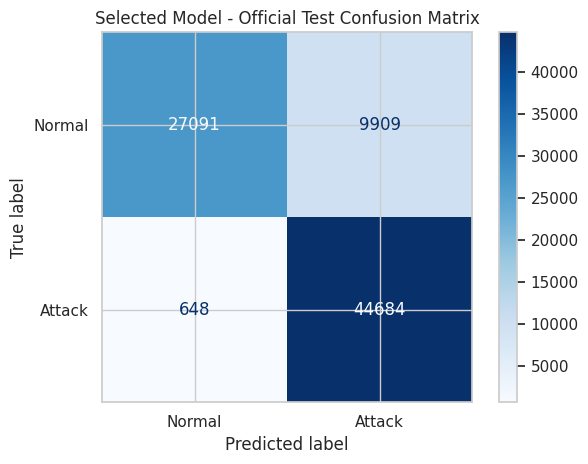

In [ ]:
best_model_name = tuning_results.iloc[0]["Model"]
best_model = tuned_models[best_model_name]
best_model.fit(X, y)

print("Selected model by training cross-validation:", best_model_name)
final_predictions = best_model.predict(X_test_official)
print("\nUntouched official test performance:")
print("Accuracy:      ", round(accuracy_score(y_test_official, final_predictions), 4))
print("Attack precision:", round(precision_score(y_test_official, final_predictions, pos_label=1, zero_division=0), 4))
print("Attack recall:   ", round(recall_score(y_test_official, final_predictions, pos_label=1, zero_division=0), 4))
print("Attack F1:       ", round(f1_score(y_test_official, final_predictions, pos_label=1, zero_division=0), 4))
print("\nClassification report:")
print(classification_report(
    y_test_official, final_predictions,
    labels=[0, 1], target_names=["Normal", "Attack"], zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test_official, final_predictions,
    labels=[0, 1], display_labels=["Normal", "Attack"], cmap="Blues"
)
plt.title("Selected Model - Official Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 13. Compare baseline and tuned results

This table places validation performance for the original models beside official test performance for the selected tuned model. **Why:** it summarizes the workflow. The validation and test scores come from different data, so use the test score as the final generalization estimate.

In [ ]:
comparison = baseline_results.copy()
comparison["Stage"] = "Baseline validation"
tuned_final = pd.DataFrame([{
    "Model": best_model_name,
    "Accuracy": accuracy_score(y_test_official, final_predictions),
    "Attack precision": precision_score(y_test_official, final_predictions, pos_label=1, zero_division=0),
    "Attack recall": recall_score(y_test_official, final_predictions, pos_label=1, zero_division=0),
    "Attack F1": f1_score(y_test_official, final_predictions, pos_label=1, zero_division=0),
    "Stage": "Tuned model, official test"
}])
comparison["Stage"] = "Baseline validation"
comparison = pd.concat([comparison, tuned_final], ignore_index=True)
display(comparison[["Model", "Stage", "Accuracy", "Attack precision", "Attack recall", "Attack F1"]].round(4))

,Model,Stage,Accuracy,Attack precision,Attack recall,Attack F1
0,Random Forest,Baseline validation,0.9591,0.9641,0.9762,0.9701
1,Decision Tree,Baseline validation,0.9479,0.9626,0.9609,0.9617
2,Logistic Regression,Baseline validation,0.9326,0.9502,0.9509,0.9505
3,Random Forest,"Tuned model, official test",0.8718,0.8185,0.9857,0.8944


## 14. Save the complete best pipeline

The fitted pipeline includes imputers, scaling, category encoding, and the classifier. **Why:** saving preprocessing together with the classifier ensures future records are transformed in exactly the same way as training records.

In [ ]:
model_path = Path("network_intrusion_detector.joblib")
joblib.dump(best_model, model_path)
print("Saved the selected model and preprocessing pipeline to:", model_path.resolve())

Saved the selected model and preprocessing pipeline to: /content/network_intrusion_detector.joblib


In [ ]:
# Create sample records without their actual labels

new_traffic = X_test_official.head(10).copy()

sample_path = "/content/new_network_traffic.csv"

new_traffic.to_csv(sample_path, index=False)

print("Sample traffic CSV created!")
print("File:", sample_path)

display(new_traffic.head())

Sample traffic CSV created!
File: /content/new_network_traffic.csv


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
0,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0
3,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0


## 15. Classify new network traffic

Choose whether to enter one record manually or load a CSV containing new records. The CSV option is best when you already have a flow record exported from a network-analysis tool. Manual entry asks for every model input and shows common values or the typical numeric range from the training data. **Only enter records you are authorized to analyze.** This project demonstrates classification; it is not a production security monitor.

In [ ]:
loaded_model = joblib.load(model_path)
mode = input("New record input: type M for manual feature entry or C for a CSV file: ").strip().upper()

if mode == "C":
    new_csv_path = input(
        "Path to CSV of new traffic records (must contain all model feature columns): "
    ).strip().strip('"').strip("'")
    new_records = pd.read_csv(new_csv_path, low_memory=False)
    missing_new = [column for column in feature_columns if column not in new_records.columns]
    if missing_new:
        raise ValueError("New-record CSV is missing these required columns: " + ", ".join(missing_new))
    new_X = new_records[feature_columns].copy()

elif mode == "M":
    print("Enter values for the network-flow feature fields below.")
    print("For a numeric feature, enter a number; press Enter to use the training median.")
    print("For a category, enter a value shown in the examples; type - if unknown.")
    manual_record = {}
    for feature in feature_columns:
        if feature in numeric_features:
            numeric_values = pd.to_numeric(X_train[feature], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
            if len(numeric_values):
                low, high = numeric_values.quantile([0.05, 0.95]).tolist()
                hint = f"typical training range {low:.4g} to {high:.4g}"
            else:
                hint = "numeric value"
            raw_value = input(f"{feature} ({hint}; blank = median): ").strip()
            if raw_value == "":
                manual_record[feature] = np.nan
            else:
                try:
                    manual_record[feature] = float(raw_value)
                except ValueError as exc:
                    raise ValueError(f"Enter a number or leave {feature} blank.") from exc
        else:
            examples = X_train[feature].astype("string").value_counts().head(8).index.tolist()
            raw_value = input(
                f"{feature} (categorical; examples: {', '.join(map(str, examples))}; - = unknown): "
            ).strip()
            manual_record[feature] = np.nan if raw_value == "-" else raw_value
    new_X = pd.DataFrame([manual_record], columns=feature_columns)
else:
    raise ValueError("Choose M for manual entry or C for a CSV file, then rerun this section.")

new_predictions = loaded_model.predict(new_X)
if hasattr(loaded_model, "predict_proba"):
    attack_probabilities = loaded_model.predict_proba(new_X)[:, 1]
else:
    attack_probabilities = [np.nan] * len(new_X)

prediction_labels = ["Malicious Traffic" if value == 1 else "Normal Traffic" for value in new_predictions]
prediction_results = pd.DataFrame({
    "Predicted class": prediction_labels,
    "Attack probability": attack_probabilities
})
print("\nNetwork Intrusion Detection Result:")
display(prediction_results)

New record input: type M for manual feature entry or C for a CSV file: c
Path to CSV of new traffic records (must contain all model feature columns): /content/new_network_traffic.csv

Network Intrusion Detection Result:


,Predicted class,Attack probability
0,Malicious Traffic,0.717642
1,Malicious Traffic,0.890000
2,Malicious Traffic,0.651773
3,Malicious Traffic,0.840000
4,Malicious Traffic,0.710000
5,Malicious Traffic,0.726696
6,Malicious Traffic,0.700000
7,Malicious Traffic,0.743841
8,Normal Traffic,0.000000
9,Normal Traffic,0.000000


## 16. How to read the output and project limitations

- **Attack recall** is important because low recall means more malicious records were missed (false negatives). **Precision** indicates how many attack alerts were actually attacks. Compare both alongside F1 and accuracy.
- The model predicts from the engineered flow features in UNSW-NB15. Live traffic must first be converted into the same feature definitions and units; raw packet captures cannot be entered directly into this model.
- The dataset includes simulated attacks and a prepared train/test split. Results on this benchmark do not guarantee detection of new real-world attacks.
- The manual-entry path asks for many fields; use the CSV input route when traffic features are already available from a compatible flow exporter.
- For a multiclass extension, use `attack_cat` as the target, remove `label` as an input too, and retrain with multiclass metrics. Do not mix the binary and multiclass target columns as model inputs.
- For academic use, cite the dataset papers listed on the official UNSW-NB15 page.
